# 03 · Bayesian and frequentist intervals at low statistics

**What this notebook does.** With the full sample ($\sim2\times10^4$ candidates) the posterior of $A_{\rm raw}$ is
Gaussian and, with flat priors, the credible interval and the profile-likelihood confidence interval coincide
numerically (notebooks 01 and 02). This notebook looks for the regime in which the two methods differ: the *same*
likelihood is analysed both ways on pseudo-datasets of 50, 150, 500 and 2000 candidates, and the **coverage** (does
the 68 %/95 % interval contain the true value 68 %/95 % of the time?), the bias and the shape of the intervals are
compared.

The pseudo-datasets are generated from the fit to the data of a **minimal six-parameter model** (window
$[5150,5450]$ MeV, Gaussian signal, one exponential background, shape and yield shared by the two charges; the
background asymmetry is fixed to zero). It is identifiable down to a few tens of events, which the twelve-parameter
nominal model is not. For each pseudo-dataset:

| method | estimator | interval |
|---|---|---|
| Bayesian | `emcee` posterior, flat priors | median, equal-tailed 68 %/95 % credible interval |
| frequentist | maximum likelihood with `iminuit` (MIGRAD) of the same $-\ln L$ | Hesse (symmetric, $\pm\sigma$, $\pm2\sigma$) and Minos (profile likelihood, Wilks) 68 %/95 % |

The model and the sampler are in `bayes_model.py`; the toy generator and the frequentist fit in `lowstat.py`.

### What goes into the report

| Section | Report |
|---|---|
| 1 | Appendix *Bayesian analysis → Minimal model as a cross-check*: $A_{\rm raw}$ and interval |
| 3 | Appendix *Comparison of the two approaches → Bayesian and frequentist intervals at low statistics*; figure `bayes_nominal_lowstat` |
| 4 | Appendix *Validation → Asymptotic behavior of the estimator* (skewness, kurtosis, normality, scaling with $N$) |

### How to run
About 2.5 h on 9 cores for the 1200 pseudo-datasets (one emcee chain of 4000 steps and one MIGRAD+HESSE+MINOS per
dataset). The block resumes from `results/lowstat/toys.jsonl`: with the saved results the notebook takes seconds.
Delete `results/lowstat/` to recompute everything.

## 0 · Setup

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, ".")
sys.path.insert(0, "..")
import bayes_model as bn
import lowstat as ls
import plot_style as ps
ps.use(); C = ps.COLORS

DATA_DIR = "../../opendata-project/Data"
OUT      = os.path.join(os.getcwd(), "results", "lowstat"); os.makedirs(OUT, exist_ok=True)
FIG_DIR  = os.path.join(os.getcwd(), "figures");           os.makedirs(FIG_DIR, exist_ok=True)

N_GRID    = [50, 150, 500, 2000]      # candidates per pseudo-dataset
N_TOYS    = 300                       # pseudo-datasets per size
NSTEPS    = 4000                      # emcee chain of each pseudo-dataset
N_WORKERS = max(1, (os.cpu_count() or 2) - 1)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name)); plt.show(); print("[saved]", os.path.join("figures", name))
print("model:", ls.CFG)

model: Config(name='lowstat', lo=5150.0, hi=5450.0, nexp=1, shape='shared', asym='sym', signal='gauss', A_bound=1.0, veto=(), signal_per_charge=False, prob_k_min=0.5, prob_pi_max=0.5)


## 1 · The minimal model fitted to the data (truth of the pseudo-datasets)

The posterior is sampled with `emcee` (flat priors, 10 000 steps). Its maximum (the maximum-likelihood estimate with
flat priors) is the **truth** used to generate the pseudo-datasets, with the yields rescaled to the sample size and
Poisson-fluctuated; the minimal model is also a cross-check of the nominal result, because its mass window and
background are different.

In [2]:
path = os.path.join(OUT, "truth.json")
if os.path.exists(path):
    truth = json.load(open(path)); print("[resume]", os.path.relpath(path))
else:
    d = bn.select(bn.load_candidates(DATA_DIR), ls.CFG)
    r = bn.fit(d.m.to_numpy(), d.q.to_numpy(), ls.CFG, nsteps=10000)
    truth = {"n": r["n"], "map": r["map"], "A": r["A"], "chain_over_tau_min": r["chain_over_tau_min"]}
    json.dump(truth, open(path, "w"), indent=1); print("[saved]", os.path.relpath(path))
print(f"candidates in [{ls.CFG.lo:.0f},{ls.CFG.hi:.0f}] MeV: {truth['n']}")
print("maximum of the posterior:", {k: round(v, 5) for k, v in truth["map"].items()})
a = truth["A"]
print(f"A_raw = {a['median']:.4f}   68% CI [{a['ci68'][0]:.4f}, {a['ci68'][1]:.4f}]   95% CI [{a['ci95'][0]:.4f}, {a['ci95'][1]:.4f}]")

[resume] results/lowstat/truth.json
candidates in [5150,5450] MeV: 17839
maximum of the posterior: {'N_s': 15283.69879, 'N_b': 2555.30122, 'A': -0.04963, 'mu': 5284.41191, 'sigma': 17.94415, 'lam1_all': 0.0031}
A_raw = -0.0494   68% CI [-0.0577, -0.0411]   95% CI [-0.0658, -0.0329]


## 2 · Pseudo-datasets

For each size $N$ and each of 300 seeds: generate $(m,q)$ from the model at the truth, fit it with the Bayesian
sampler (starting from the true parameters), fit it again by maximum likelihood with `iminuit`, and record whether
each of the intervals contains the true $A$. Every dataset is independent, so they run in parallel; each result is
appended to `toys.jsonl`.

In [3]:
tasks = [(f"{N}_{i}", N, truth["map"], 100000 * N + i, NSTEPS) for N in N_GRID for i in range(N_TOYS)]
toys = bn.run_parallel(tasks, ls.task, os.path.join(OUT, "toys.jsonl"), key=lambda r: r["key"], n_workers=N_WORKERS, log_every=50)
print(len(toys), "pseudo-datasets")

results/lowstat/toys.jsonl: 1200 already done, 0 to run


1200 pseudo-datasets


## 3 · Coverage, bias and interval shape against the sample size

Per size $N$: the fraction of toys in which the interval contains the truth (coverage, with binomial error) for the
Bayesian credible interval, the Minos interval and the Hesse interval; the bias of the Bayesian median and of the
MLE; the mean difference $|{\rm median}-{\rm MLE}|$ (how much the two point estimates differ); and the mean
asymmetry of the credible interval around the median.

**Figure `bayes_nominal_lowstat`.** Coverage of the 68 % (a) and 95 % (b) intervals against $N$ for the three
methods; the dashed line is the nominal level.

N=   50  cov68: Bayes 0.720+-0.026  Minos 0.703  Hesse 0.697 | cov95: Bayes 0.940  Minos 0.927  Hesse 0.923 | bias med -0.0070  MLE -0.0085 | |med-MLE| 0.0075 | valid 1.000
N=  150  cov68: Bayes 0.673+-0.027  Minos 0.670  Hesse 0.670 | cov95: Bayes 0.950  Minos 0.947  Hesse 0.947 | bias med -0.0044  MLE -0.0051 | |med-MLE| 0.0024 | valid 1.000
N=  500  cov68: Bayes 0.683+-0.027  Minos 0.687  Hesse 0.687 | cov95: Bayes 0.937  Minos 0.937  Hesse 0.937 | bias med -0.0021  MLE -0.0022 | |med-MLE| 0.0011 | valid 1.000
N= 2000  cov68: Bayes 0.717+-0.026  Minos 0.723  Hesse 0.723 | cov95: Bayes 0.983  Minos 0.987  Hesse 0.987 | bias med +0.0010  MLE +0.0009 | |med-MLE| 0.0006 | valid 1.000
[saved] results/lowstat/summary.json


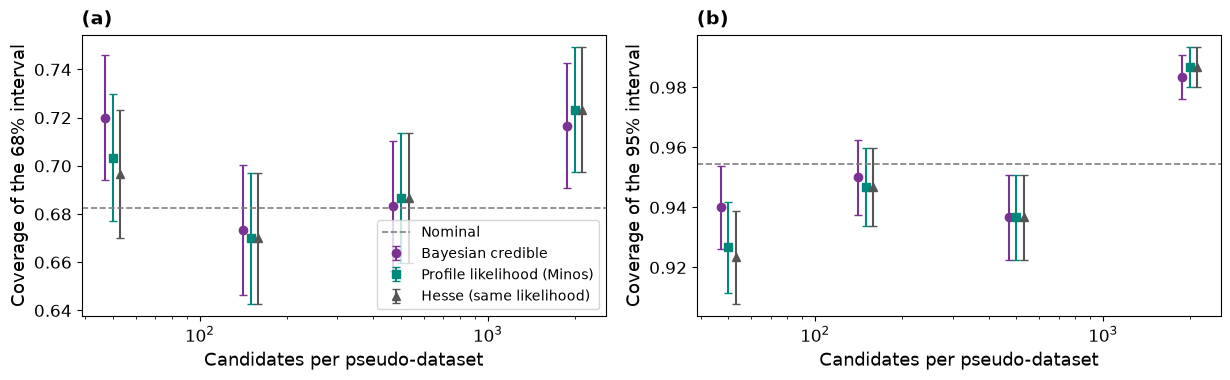

[saved] figures/bayes_nominal_lowstat.pdf


In [4]:
def frac(v):
    v = [x for x in v if x is not None]
    p = float(np.mean(v)); return p, float(np.sqrt(p * (1 - p) / len(v))), len(v)

summary = {}
for N in N_GRID:
    t = [x for x in toys if x["n_total"] == N]
    a0 = t[0]["A_true"]
    b_med = np.array([x["bayes"]["median"] for x in t]); f_hat = np.array([x["freq"]["A"] for x in t])
    b_sd  = np.array([x["bayes"]["sd"] for x in t]);     f_he  = np.array([x["freq"]["hesse"] for x in t])
    s = {"n_toys": len(t), "A_true": a0, "mean_n": float(np.mean([x["n"] for x in t]))}
    for lab, key in (("bayes68", ("bayes", "in68")), ("bayes95", ("bayes", "in95")),
                     ("minos68", ("freq", "in68_minos")), ("minos95", ("freq", "in95_minos")),
                     ("hesse68", ("freq", "in68_hesse")), ("hesse95", ("freq", "in95_hesse"))):
        s[lab] = frac([x[key[0]][key[1]] for x in t])
    s["bias_bayes_median"] = [float(np.mean(b_med - a0)), float(np.std(b_med) / np.sqrt(len(t)))]
    s["bias_mle"] = [float(np.nanmean(f_hat - a0)), float(np.nanstd(f_hat) / np.sqrt(len(t)))]
    s["spread_bayes_median"] = float(np.std(b_med)); s["spread_mle"] = float(np.nanstd(f_hat))
    s["mean_posterior_sd"] = float(np.mean(b_sd)); s["mean_hesse"] = float(np.nanmean(f_he))
    s["mean_abs_median_minus_mle"] = float(np.nanmean(np.abs(b_med - f_hat)))
    s["mean_rel_ci68_asymmetry"] = float(np.mean([x["bayes"]["skew_68"] / (x["bayes"]["ci68"][1] - x["bayes"]["ci68"][0]) for x in t]))
    s["frac_freq_valid"] = float(np.mean([x["freq"]["valid"] for x in t]))
    s["min_chain_over_tau"] = float(np.min([x["bayes"]["chain_over_tau_min"] for x in t]))
    summary[N] = s
    print(f"N={N:5d}  cov68: Bayes {s['bayes68'][0]:.3f}+-{s['bayes68'][1]:.3f}  Minos {s['minos68'][0]:.3f}  Hesse {s['hesse68'][0]:.3f} | "
          f"cov95: Bayes {s['bayes95'][0]:.3f}  Minos {s['minos95'][0]:.3f}  Hesse {s['hesse95'][0]:.3f} | "
          f"bias med {s['bias_bayes_median'][0]:+.4f}  MLE {s['bias_mle'][0]:+.4f} | |med-MLE| {s['mean_abs_median_minus_mle']:.4f} | valid {s['frac_freq_valid']:.3f}")
json.dump({"N_grid": N_GRID, "summary": summary, "model": "lowstat (6 parameters, [5150,5450])"},
          open(os.path.join(OUT, "summary.json"), "w"), indent=1)
print("[saved]", os.path.join("results", "lowstat", "summary.json"))

fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.0))
for a_, lvl, nomv in ((axs[0], "68", 0.6827), (axs[1], "95", 0.9545)):
    for k, (key, lab, col, mk) in enumerate((("bayes", "Bayesian credible", C["bayes"], "o"),
                                             ("minos", "Profile likelihood (Minos)", C["freq"], "s"),
                                             ("hesse", "Hesse (same likelihood)", C["count"], "^"))):
        x = np.array(N_GRID) * (1 + 0.06 * (k - 1))
        a_.errorbar(x, [summary[n][key + lvl][0] for n in N_GRID], yerr=[summary[n][key + lvl][1] for n in N_GRID],
                    fmt=mk, color=col, capsize=3, label=lab)
    a_.axhline(nomv, color=C["background"], ls="--", lw=1.2, label="Nominal")
    a_.set_xscale("log"); a_.set_xlabel("Candidates per pseudo-dataset"); a_.set_ylabel(f"Coverage of the {lvl}% interval")
    ps.letter(a_, "a" if lvl == "68" else "b")
axs[0].legend(loc="lower right", fontsize=10)
plt.tight_layout()
save_fig(fig, "bayes_nominal_lowstat.pdf")

## 4 · Normality and scaling of the estimator

How fast does the estimator approach the asymptotic regime? For each $N$: the bias of the MLE, its spread, the
skewness and excess kurtosis of its distribution over the toys, the $p$-value of the Shapiro–Wilk test of normality,
the product $\mathrm{sd}\cdot\sqrt N$ (constant if the error scales as $1/\sqrt N$), the linear error propagation
$\sqrt{(1-A^2)/N_s}$ (signal events only) and the mean Hesse uncertainty.

In [5]:
f_sig = truth["map"]["N_s"] / (truth["map"]["N_s"] + truth["map"]["N_b"])
a_true = truth["map"]["A"]
rows = {}
print(f"{'N':>5s} {'valid':>5s} {'bias':>8s} {'sd':>8s} {'skew':>6s} {'ex.kurt':>8s} {'Shapiro p':>10s} {'sd*sqrtN':>9s} {'lin.prop.':>10s} {'<Hesse>':>8s}")
for n in sorted({t["n_total"] for t in toys}):
    sel = [t for t in toys if t["n_total"] == n and t["freq"].get("valid")]
    a = np.array([t["freq"]["A"] for t in sel])
    rows[str(n)] = dict(n_toys=len(a), mean_bias=float(a.mean() - a_true), sd=float(a.std(ddof=1)),
                        skewness=float(stats.skew(a)), excess_kurtosis=float(stats.kurtosis(a)),
                        shapiro_p=float(stats.shapiro(a).pvalue), sd_times_sqrtN=float(a.std(ddof=1) * np.sqrt(n)),
                        linear_propagation_signal_only=float(np.sqrt((1 - a_true ** 2) / (f_sig * n))),
                        mean_hesse=float(np.mean([t["freq"]["hesse"] for t in sel])))
    r = rows[str(n)]
    print(f"{n:5d} {len(a):5d} {r['mean_bias']:+8.4f} {r['sd']:8.4f} {r['skewness']:+6.2f} {r['excess_kurtosis']:+8.2f} "
          f"{r['shapiro_p']:10.3f} {r['sd_times_sqrtN']:9.3f} {r['linear_propagation_signal_only']:10.4f} {r['mean_hesse']:8.4f}")
json.dump(rows, open(os.path.join(OUT, "scaling.json"), "w"), indent=1)
print("[saved]", os.path.join("results", "lowstat", "scaling.json"))

    N valid     bias       sd   skew  ex.kurt  Shapiro p  sd*sqrtN  lin.prop.  <Hesse>
   50   300  -0.0085   0.1611  -0.15    +0.64      0.029     1.139     0.1526   0.1529
  150   300  -0.0051   0.0920  +0.16    +0.31      0.592     1.127     0.0881   0.0902
  500   300  -0.0022   0.0501  -0.08    +0.38      0.516     1.121     0.0483   0.0493
 2000   300  +0.0009   0.0225  -0.20    -0.20      0.318     1.008     0.0241   0.0248
[saved] results/lowstat/scaling.json
